In [2]:
!pip install -q torch torchvision scikit-learn matplotlib seaborn


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from torch.utils.data import DataLoader, Subset
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [4]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)

train_dataset = Subset(train_dataset, range(10000))
test_dataset = Subset(test_dataset, range(2000))

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

classes = [str(i) for i in range(10)]

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Classes:", classes)

100%|██████████| 9.91M/9.91M [00:00<00:00, 58.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.66MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.6MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.4MB/s]

Training samples: 10000
Testing samples: 2000
Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


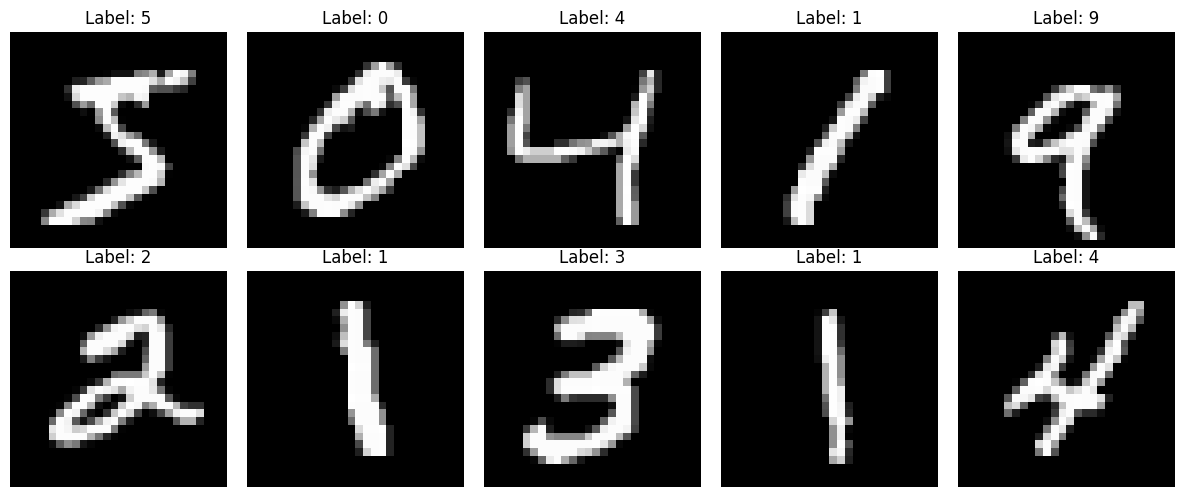

In [5]:
original_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = original_dataset[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
vit_model = models.vit_b_16(
    weights=models.ViT_B_16_Weights.DEFAULT
)

for param in vit_model.parameters():
    param.requires_grad = False

vit_model.heads.head = nn.Linear(
    vit_model.heads.head.in_features,
    10
)

vit_model = vit_model.to(device)

print("Vision Transformer loaded successfully")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:03<00:00, 94.5MB/s]


Vision Transformer loaded successfully


In [7]:
cnn_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

for param in cnn_model.parameters():
    param.requires_grad = False

cnn_model.fc = nn.Linear(
    cnn_model.fc.in_features,
    10
)

cnn_model = cnn_model.to(device)

print("ResNet18 CNN loaded successfully")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 154MB/s]

ResNet18 CNN loaded successfully


In [8]:
def train_model(model, train_loader, epochs=3):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=0.001
    )

    history = {
        "loss": [],
        "accuracy": []
    }

    start_time = time.time()

    for epoch in range(epochs):

        model.train()

        running_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = 100 * correct / total

        history["loss"].append(epoch_loss)
        history["accuracy"].append(epoch_accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} "
            f"Accuracy: {epoch_accuracy:.2f}%"
        )

    training_time = time.time() - start_time

    return history, training_time

In [9]:
print("Training Vision Transformer")

vit_history, vit_time = train_model(
    vit_model,
    train_loader,
    epochs=3
)

print("ViT Training Time:", round(vit_time, 2), "seconds")

Training Vision Transformer
Epoch [1/3] Loss: 0.5255 Accuracy: 86.79%
Epoch [2/3] Loss: 0.2177 Accuracy: 94.32%
Epoch [3/3] Loss: 0.1728 Accuracy: 95.01%
ViT Training Time: 374.57 seconds


In [10]:
print("Training ResNet18 CNN")

cnn_history, cnn_time = train_model(
    cnn_model,
    train_loader,
    epochs=3
)

print("CNN Training Time:", round(cnn_time, 2), "seconds")

Training ResNet18 CNN
Epoch [1/3] Loss: 0.9321 Accuracy: 76.03%
Epoch [2/3] Loss: 0.4447 Accuracy: 88.68%
Epoch [3/3] Loss: 0.3644 Accuracy: 89.86%
CNN Training Time: 73.9 seconds


In [11]:
def evaluate_model(model, test_loader):

    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)

            outputs = model(images)

            predictions = torch.argmax(outputs, dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    return {
        "Accuracy": accuracy * 100,
        "Precision": precision * 100,
        "Recall": recall * 100,
        "F1 Score": f1 * 100,
        "True Labels": y_true,
        "Predictions": y_pred
    }

In [12]:
vit_results = evaluate_model(
    vit_model,
    test_loader
)

print("VISION TRANSFORMER RESULTS")

print("Accuracy:", round(vit_results["Accuracy"], 2), "%")
print("Precision:", round(vit_results["Precision"], 2), "%")
print("Recall:", round(vit_results["Recall"], 2), "%")
print("F1 Score:", round(vit_results["F1 Score"], 2), "%")

VISION TRANSFORMER RESULTS
Accuracy: 94.15 %
Precision: 94.24 %
Recall: 94.15 %
F1 Score: 94.14 %


In [13]:
cnn_results = evaluate_model(
    cnn_model,
    test_loader
)

print("RESNET18 CNN RESULTS")


print("Accuracy:", round(cnn_results["Accuracy"], 2), "%")
print("Precision:", round(cnn_results["Precision"], 2), "%")
print("Recall:", round(cnn_results["Recall"], 2), "%")
print("F1 Score:", round(cnn_results["F1 Score"], 2), "%")

RESNET18 CNN RESULTS
Accuracy: 89.15 %
Precision: 89.45 %
Recall: 89.15 %
F1 Score: 89.1 %


In [14]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "Training Time"
    ],

    "Vision Transformer": [
        vit_results["Accuracy"],
        vit_results["Precision"],
        vit_results["Recall"],
        vit_results["F1 Score"],
        vit_time
    ],

    "CNN (ResNet18)": [
        cnn_results["Accuracy"],
        cnn_results["Precision"],
        cnn_results["Recall"],
        cnn_results["F1 Score"],
        cnn_time
    ]
})

print(comparison.to_string(index=False))

       Metric  Vision Transformer  CNN (ResNet18)
     Accuracy           94.150000       89.150000
    Precision           94.242233       89.446726
       Recall           94.150000       89.150000
     F1 Score           94.142408       89.103363
Training Time          374.572789       73.896497


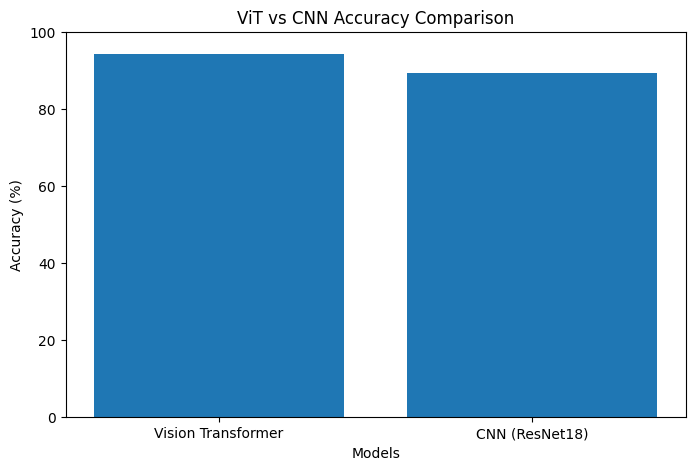

In [15]:
model_names = ["Vision Transformer", "CNN (ResNet18)"]

accuracies = [
    vit_results["Accuracy"],
    cnn_results["Accuracy"]
]

plt.figure(figsize=(8, 5))

plt.bar(model_names, accuracies)

plt.xlabel("Models")
plt.ylabel("Accuracy (%)")
plt.title("ViT vs CNN Accuracy Comparison")
plt.ylim(0, 100)

plt.show()

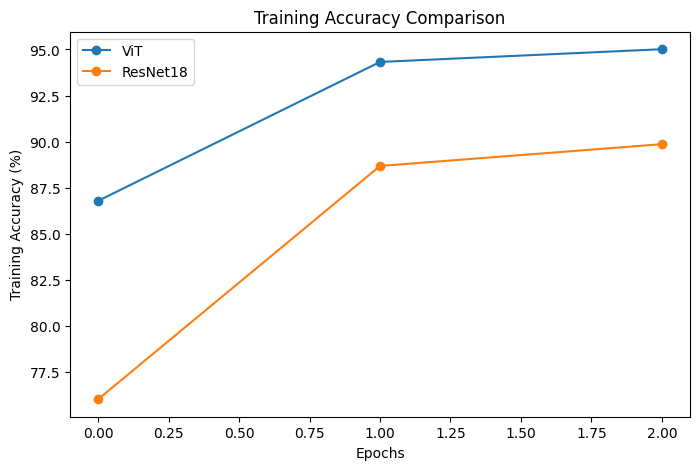

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(vit_history["accuracy"], marker="o", label="ViT")
plt.plot(cnn_history["accuracy"], marker="o", label="ResNet18")

plt.xlabel("Epochs")
plt.ylabel("Training Accuracy (%)")
plt.title("Training Accuracy Comparison")
plt.legend()

plt.show()

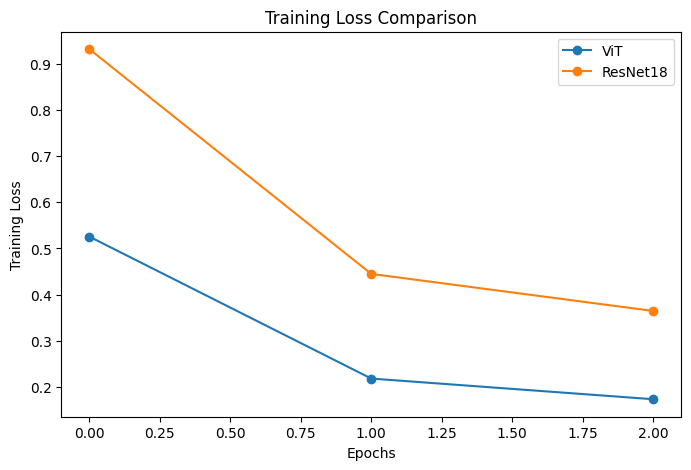

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(vit_history["loss"], marker="o", label="ViT")
plt.plot(cnn_history["loss"], marker="o", label="ResNet18")

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.legend()

plt.show()

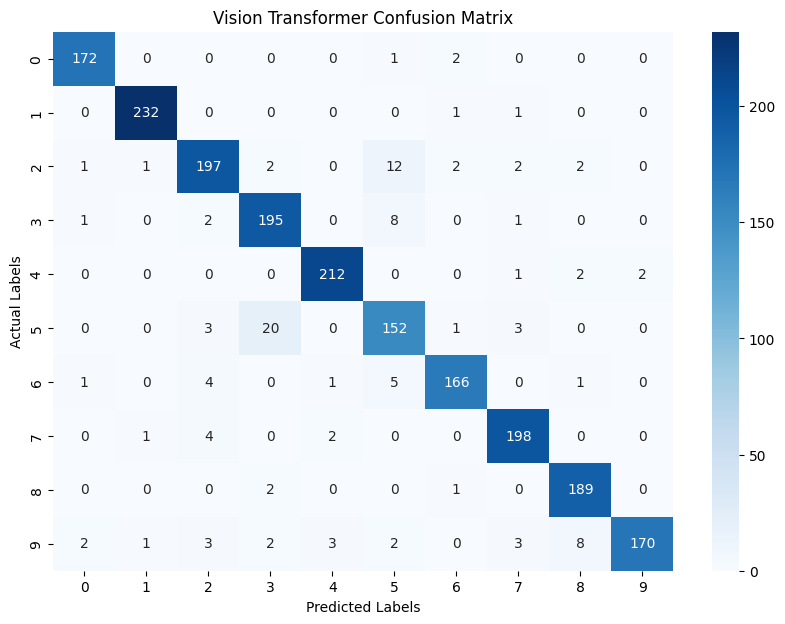

In [18]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    confusion_matrix(
        vit_results["True Labels"],
        vit_results["Predictions"]
    ),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.title("Vision Transformer Confusion Matrix")

plt.show()

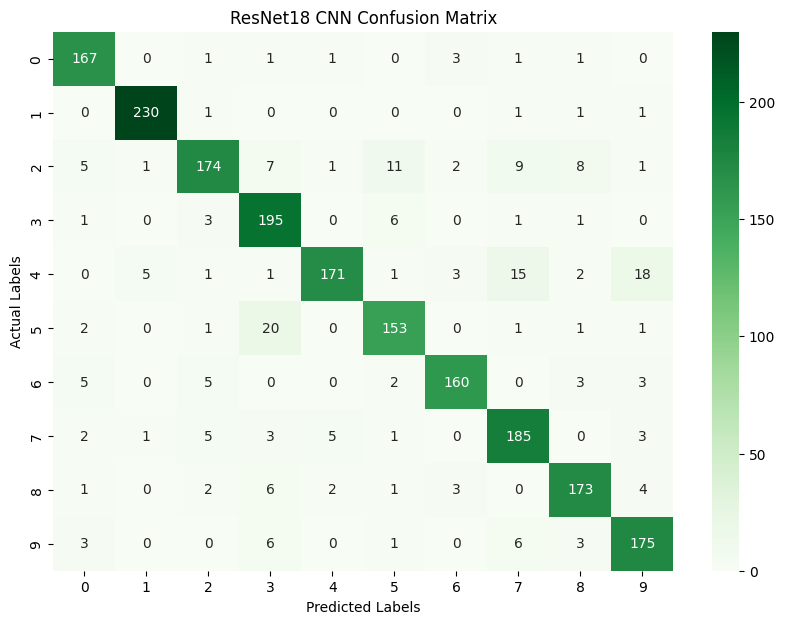

In [19]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    confusion_matrix(
        cnn_results["True Labels"],
        cnn_results["Predictions"]
    ),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.title("ResNet18 CNN Confusion Matrix")

plt.show()

In [20]:
print("VISION TRANSFORMER CLASSIFICATION REPORT")

print(
    classification_report(
        vit_results["True Labels"],
        vit_results["Predictions"],
        target_names=classes,
        zero_division=0
    )
)

print("\nCNN CLASSIFICATION REPORT")

print(
    classification_report(
        cnn_results["True Labels"],
        cnn_results["Predictions"],
        target_names=classes,
        zero_division=0
    )
)

VISION TRANSFORMER CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.97      0.98      0.98       175
           1       0.99      0.99      0.99       234
           2       0.92      0.90      0.91       219
           3       0.88      0.94      0.91       207
           4       0.97      0.98      0.97       217
           5       0.84      0.85      0.85       179
           6       0.96      0.93      0.95       178
           7       0.95      0.97      0.96       205
           8       0.94      0.98      0.96       192
           9       0.99      0.88      0.93       194

    accuracy                           0.94      2000
   macro avg       0.94      0.94      0.94      2000
weighted avg       0.94      0.94      0.94      2000


CNN CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.90      0.95      0.93       175
           1       0.97      0.98      0.98       234
          

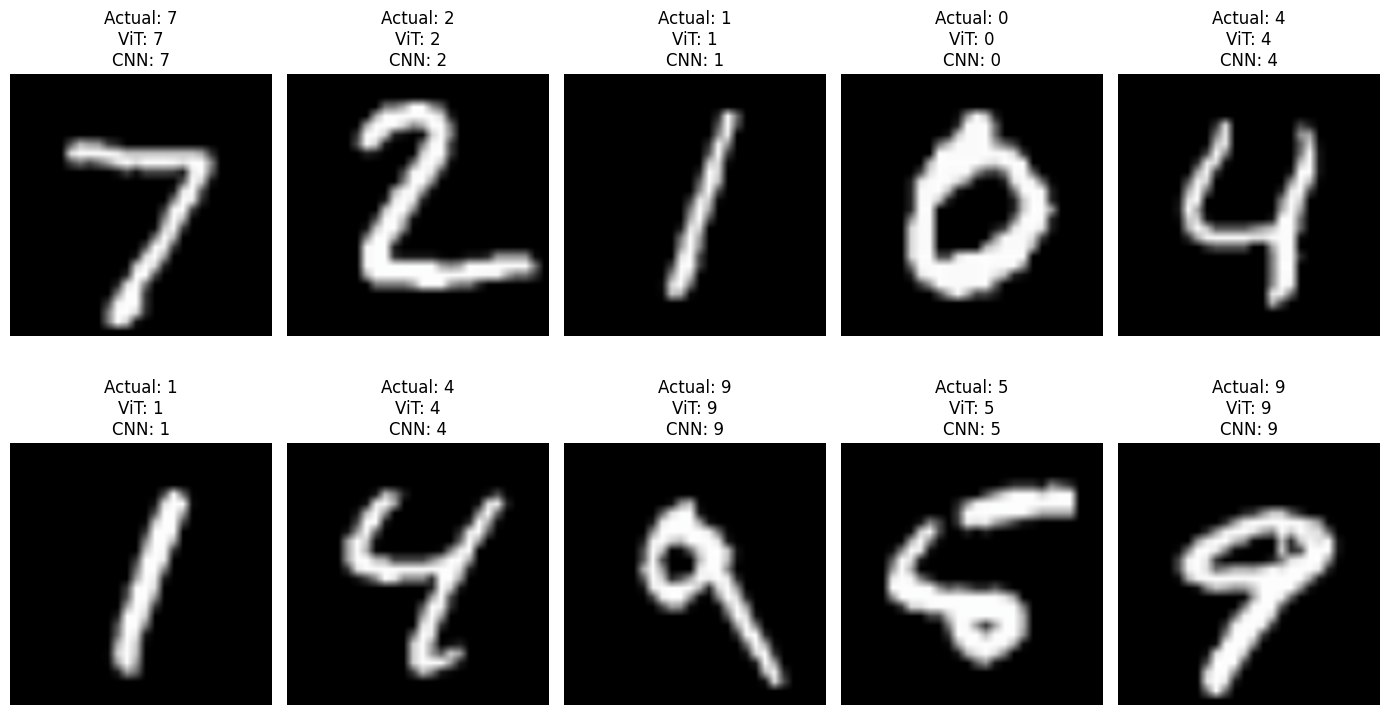

In [21]:
def predict_image(model, image):

    model.eval()

    with torch.no_grad():

        image = image.unsqueeze(0).to(device)

        output = model(image)

        prediction = torch.argmax(output, dim=1).item()

    return prediction


images, labels = next(iter(test_loader))

plt.figure(figsize=(14, 8))

for i in range(10):

    image = images[i]

    vit_prediction = predict_image(vit_model, image)
    cnn_prediction = predict_image(cnn_model, image)

    img = image.cpu().permute(1, 2, 0).numpy()

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    img = np.clip(img * std + mean, 0, 1)

    plt.subplot(2, 5, i + 1)

    plt.imshow(img)

    plt.title(
        f"Actual: {labels[i].item()}\n"
        f"ViT: {vit_prediction}\n"
        f"CNN: {cnn_prediction}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
print("FINAL MODEL COMPARISON")


print("ViT Accuracy:", round(vit_results["Accuracy"], 2), "%")
print("CNN Accuracy:", round(cnn_results["Accuracy"], 2), "%")

print("ViT Training Time:", round(vit_time, 2), "seconds")
print("CNN Training Time:", round(cnn_time, 2), "seconds")

if vit_results["Accuracy"] > cnn_results["Accuracy"]:
    print("\nVision Transformer achieved higher accuracy.")

elif cnn_results["Accuracy"] > vit_results["Accuracy"]:
    print("\nResNet18 CNN achieved higher accuracy.")

else:
    print("\nBoth models achieved equal accuracy.")

FINAL MODEL COMPARISON
ViT Accuracy: 94.15 %
CNN Accuracy: 89.15 %
ViT Training Time: 374.57 seconds
CNN Training Time: 73.9 seconds

Vision Transformer achieved higher accuracy.
